# **Retail Business Performance & Profitability Analysis**
Project Phase — Elevate Labs Data Analyst Internship

## Setup

**Import libraries**

In [ ]:
import pandas as pd
import sqlite3

**Upload and load the full dataset**

In [ ]:
from google.colab import files
uploaded = files.upload()

df = pd.read_csv('retail_store_inventory_data.csv')
print(df.shape)
df.head()

Saving retail_store_inventory_data.csv to retail_store_inventory_data (1).csv
(73100, 15)


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


**Load data into a real SQL database (SQLite, in-memory)**

In [ ]:
conn = sqlite3.connect(':memory:')
df.to_sql('sales', conn, index=False, if_exists='replace')
print("Loaded into SQLite successfully")

Loaded into SQLite successfully


**Confirm the full dataset loaded correctly**

In [ ]:
query = "SELECT COUNT(*) AS total_rows FROM sales;"
result = pd.read_sql_query(query, conn)
print(result)

   total_rows
0       73100


## SQL Analysis: Profitability by Category
**Note:** this dataset has no cost/COGS column, so profit is estimated using
assumed category margins (documented below and in the final report).

**Query 1: Profit margin by category**

In [ ]:
query = """
SELECT
    Category,
    ROUND(SUM(Price * "Units Sold"), 2) AS total_revenue,
    ROUND(SUM(
        Price * "Units Sold" *
        CASE
            WHEN Category = 'Groceries' THEN 0.20
            WHEN Category = 'Clothing' THEN 0.40
            WHEN Category = 'Electronics' THEN 0.25
            WHEN Category = 'Furniture' THEN 0.30
            WHEN Category = 'Toys' THEN 0.35
            ELSE 0.30
        END
    ), 2) AS estimated_profit,
    COUNT(*) AS num_transactions
FROM sales
GROUP BY Category
ORDER BY estimated_profit DESC;
"""
result = pd.read_sql_query(query, conn)
print(result)

      Category  total_revenue  estimated_profit  num_transactions
0     Clothing   1.096510e+08       43860414.80             14626
1         Toys   1.096424e+08       38374855.47             14643
2    Furniture   1.115118e+08       33453541.30             14699
3  Electronics   1.084391e+08       27109765.30             14521
4    Groceries   1.109845e+08       22196907.64             14611


## SQL Analysis: Investigating Inventory Patterns

**Attempt 1: Average inventory-to-sales ratio per product**

In [ ]:
query = """
SELECT
    "Product ID",
    Category,
    ROUND(AVG("Inventory Level"), 1) AS avg_inventory,
    ROUND(AVG("Units Sold"), 1) AS avg_units_sold,
    ROUND(AVG("Inventory Level") / NULLIF(AVG("Units Sold"), 0), 1) AS inventory_to_sales_ratio
FROM sales
GROUP BY "Product ID", Category
HAVING avg_units_sold > 0
ORDER BY inventory_to_sales_ratio DESC
LIMIT 15;
"""
result = pd.read_sql_query(query, conn)
print(result)

   Product ID     Category  avg_inventory  avg_units_sold  \
0       P0002    Furniture          280.0           131.5   
1       P0003     Clothing          273.1           131.2   
2       P0005  Electronics          273.1           132.3   
3       P0006  Electronics          280.5           136.3   
4       P0007    Furniture          275.4           133.8   
5       P0008  Electronics          277.0           134.3   
6       P0008    Furniture          273.0           130.1   
7       P0008         Toys          271.4           129.9   
8       P0010    Groceries          280.3           133.3   
9       P0010         Toys          272.7           132.8   
10      P0011         Toys          279.3           132.8   
11      P0012     Clothing          267.8           127.4   
12      P0012    Groceries          271.3           128.3   
13      P0013     Clothing          270.4           131.6   
14      P0014  Electronics          276.7           133.8   

    inventory_to_sales_

**Verifying: does inventory level actually vary by product?**

In [ ]:
query = """
SELECT
    "Product ID",
    Category,
    Region,
    Date,
    "Inventory Level",
    "Units Sold",
    ROUND("Inventory Level" * 1.0 / NULLIF("Units Sold", 0), 1) AS inventory_to_sales_ratio
FROM sales
WHERE "Units Sold" > 0
ORDER BY inventory_to_sales_ratio DESC
LIMIT 15;
"""
result = pd.read_sql_query(query, conn)
print(result)

   Product ID     Category Region        Date  Inventory Level  Units Sold  \
0       P0010  Electronics   East  2022-12-17              493           1   
1       P0011    Furniture   East  2022-06-29              490           1   
2       P0014     Clothing  South  2023-06-30              484           1   
3       P0015    Groceries   West  2022-05-26              483           1   
4       P0009     Clothing  South  2023-01-28              483           1   
5       P0019    Groceries   West  2022-05-03              479           1   
6       P0015  Electronics   East  2023-03-16              477           1   
7       P0008    Furniture  South  2022-12-16              475           1   
8       P0013    Furniture  North  2022-02-12              474           1   
9       P0011     Clothing   East  2023-03-08              474           1   
10      P0003  Electronics  North  2023-06-22              473           1   
11      P0015         Toys  South  2023-04-11              472  

**Finding:** inventory levels appear near-uniformly distributed across products.
This data isn't reliable for identifying specific overstocked products,
so we pivot to demand-driven patterns instead.

**Attempt 2: Row-level overstock snapshots**

In [ ]:
query = """
SELECT
    "Product ID",
    COUNT(*) AS num_records,
    ROUND(AVG("Inventory Level"), 1) AS avg_inventory,
    ROUND(MIN("Inventory Level"), 1) AS min_inventory,
    ROUND(MAX("Inventory Level"), 1) AS max_inventory,
    ROUND(AVG("Units Sold"), 1) AS avg_units_sold
FROM sales
GROUP BY "Product ID"
ORDER BY "Product ID"
LIMIT 20;
"""
result = pd.read_sql_query(query, conn)
print(result)

   Product ID  num_records  avg_inventory  min_inventory  max_inventory  \
0       P0001         3655          273.0           50.0          500.0   
1       P0002         3655          271.1           50.0          500.0   
2       P0003         3655          274.9           50.0          500.0   
3       P0004         3655          271.6           50.0          500.0   
4       P0005         3655          273.0           50.0          500.0   
5       P0006         3655          273.6           50.0          500.0   
6       P0007         3655          274.7           50.0          500.0   
7       P0008         3655          272.8           50.0          500.0   
8       P0009         3655          275.3           50.0          500.0   
9       P0010         3655          274.9           50.0          500.0   
10      P0011         3655          272.8           50.0          500.0   
11      P0012         3655          272.5           50.0          500.0   
12      P0013         365

## SQL Analysis: What Actually Drives Sales?

**Does Holiday/Promotion affect sales volume?**

In [ ]:
query = """
SELECT
    "Holiday/Promotion",
    ROUND(AVG("Units Sold"), 1) AS avg_units_sold,
    ROUND(AVG(Discount), 1) AS avg_discount,
    COUNT(*) AS num_records
FROM sales
GROUP BY "Holiday/Promotion";
"""
result = pd.read_sql_query(query, conn)
print(result)

   Holiday/Promotion  avg_units_sold  avg_discount  num_records
0                  0           136.5          10.0        36747
1                  1           136.4          10.0        36353


**Does Seasonality affect sales volume?**

In [ ]:
query = """
SELECT
    Seasonality,
    ROUND(AVG("Units Sold"), 1) AS avg_units_sold,
    ROUND(SUM(Price * "Units Sold"), 0) AS total_revenue
FROM sales
GROUP BY Seasonality
ORDER BY avg_units_sold DESC;
"""
result = pd.read_sql_query(query, conn)
print(result)

  Seasonality  avg_units_sold  total_revenue
0      Autumn           137.8    138059214.0
1      Winter           136.8    138269587.0
2      Spring           135.8    137112310.0
3      Summer           135.4    136787773.0


## Full Correlation Analysis

**Correlation matrix across all numeric variables**

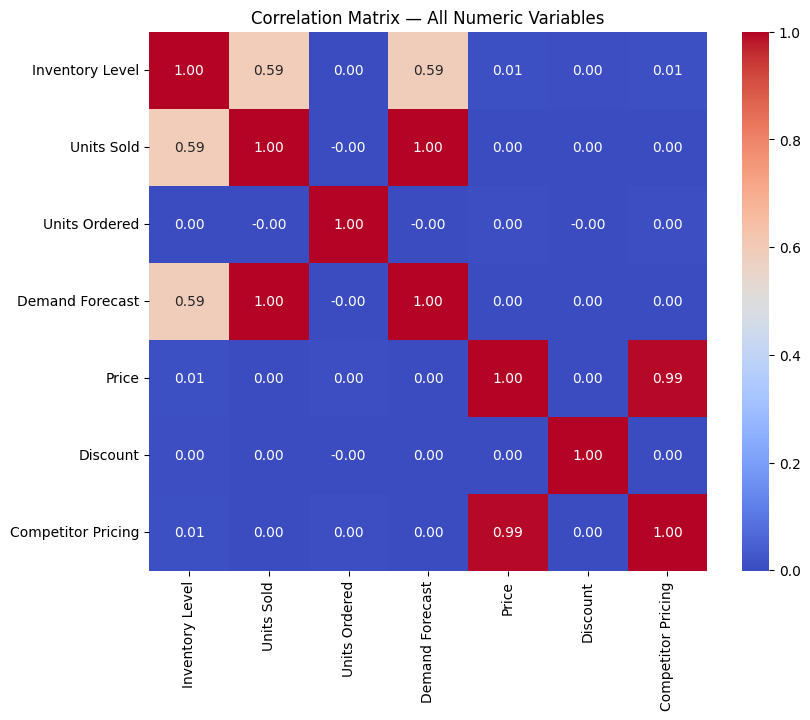

                    Inventory Level  Units Sold  Units Ordered  \
Inventory Level            1.000000    0.589995       0.001060   
Units Sold                 0.589995    1.000000      -0.000930   
Units Ordered              0.001060   -0.000930       1.000000   
Demand Forecast            0.588561    0.996853      -0.001102   
Price                      0.009140    0.001082       0.004212   
Discount                   0.004889    0.002576      -0.000938   
Competitor Pricing         0.009365    0.001259       0.004596   

                    Demand Forecast     Price  Discount  Competitor Pricing  
Inventory Level            0.588561  0.009140  0.004889            0.009365  
Units Sold                 0.996853  0.001082  0.002576            0.001259  
Units Ordered             -0.001102  0.004212 -0.000938            0.004596  
Demand Forecast            1.000000  0.000675  0.002338            0.000844  
Price                      0.000675  1.000000  0.001509            0.993900  
Dis

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = ['Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast',
                 'Price', 'Discount', 'Competitor Pricing']
corr = df[numeric_cols].corr()

plt.figure(figsize=(9,7))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix — All Numeric Variables')
plt.show()

print(corr)

## Core Finding: The Ordering Gap

**Units Ordered vs Units Sold, by category**

In [ ]:
query = """
SELECT
    Category,
    ROUND(AVG("Units Ordered"), 1) AS avg_units_ordered,
    ROUND(AVG("Units Sold"), 1) AS avg_units_sold,
    ROUND(AVG("Units Ordered") - AVG("Units Sold"), 1) AS ordering_gap
FROM sales
GROUP BY Category
ORDER BY ordering_gap DESC;
"""
result = pd.read_sql_query(query, conn)
print(result)

      Category  avg_units_ordered  avg_units_sold  ordering_gap
0  Electronics              109.7           135.0         -25.3
1         Toys              110.0           135.9         -26.0
2     Clothing              110.4           136.7         -26.3
3    Groceries              109.9           136.9         -27.0
4    Furniture              110.1           137.8         -27.7


## Python Analysis: Inventory Turnover vs Profitability

**Calculate a days-of-supply metric**

In [ ]:
df['days_of_supply'] = df['Inventory Level'] / df['Units Sold'].replace(0, 1)

print(df['days_of_supply'].describe())

count    73100.000000
mean         7.138150
std         26.648372
min          1.000000
25%          1.335605
50%          2.017817
75%          4.054545
max        500.000000
Name: days_of_supply, dtype: float64


**Calculate estimated profit and correlate with days-of-supply**

In [ ]:
margin_map = {
    'Groceries': 0.20, 'Clothing': 0.40, 'Electronics': 0.25,
    'Furniture': 0.30, 'Toys': 0.35
}
df['margin'] = df['Category'].map(margin_map)
df['estimated_profit'] = df['Price'] * df['Units Sold'] * df['margin']

# Pearson (linear) and Spearman (rank-based, better for skewed data) correlation
pearson_corr = df['days_of_supply'].corr(df['estimated_profit'], method='pearson')
spearman_corr = df['days_of_supply'].corr(df['estimated_profit'], method='spearman')

print(f"Pearson correlation: {pearson_corr:.4f}")
print(f"Spearman correlation: {spearman_corr:.4f}")

Pearson correlation: -0.1828
Spearman correlation: -0.6461


**Visualize: Days of Supply vs Profit (log scale)**

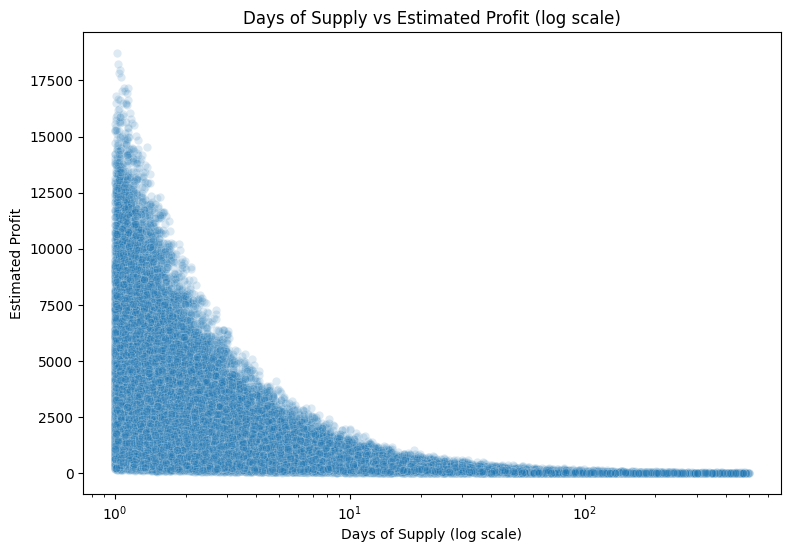

In [ ]:
plt.figure(figsize=(9,6))
sns.scatterplot(x='days_of_supply', y='estimated_profit', data=df, alpha=0.15)
plt.xscale('log')  # log scale since days_of_supply is heavily skewed
plt.title('Days of Supply vs Estimated Profit (log scale)')
plt.xlabel('Days of Supply (log scale)')
plt.ylabel('Estimated Profit')
plt.show()

**Visualize: same chart, by category (single overlapping plot — hard to read)**

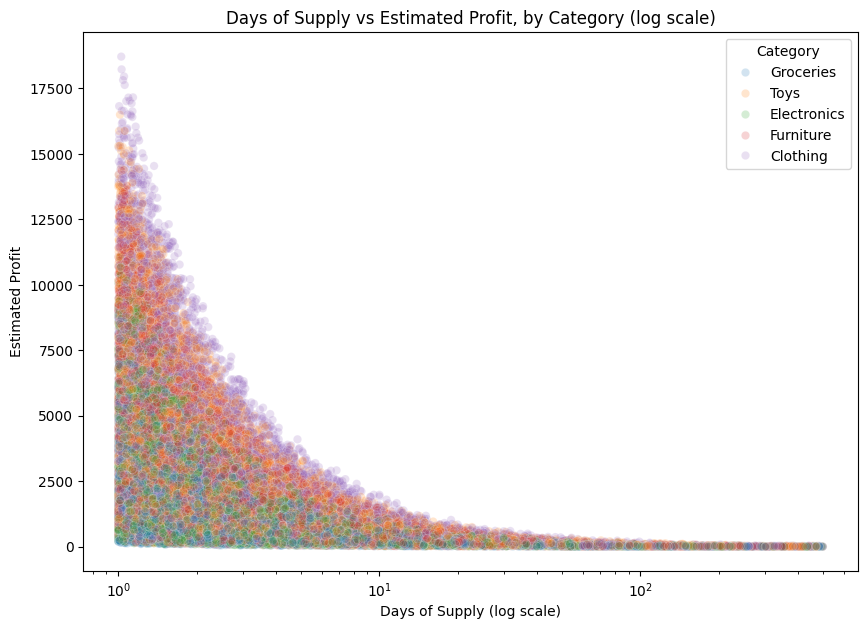

In [ ]:
plt.figure(figsize=(10,7))
sns.scatterplot(x='days_of_supply', y='estimated_profit', hue='Category', data=df, alpha=0.2)
plt.xscale('log')
plt.title('Days of Supply vs Estimated Profit, by Category (log scale)')
plt.xlabel('Days of Supply (log scale)')
plt.ylabel('Estimated Profit')
plt.show()

**Visualize: faceted version, one panel per category (clearer)**

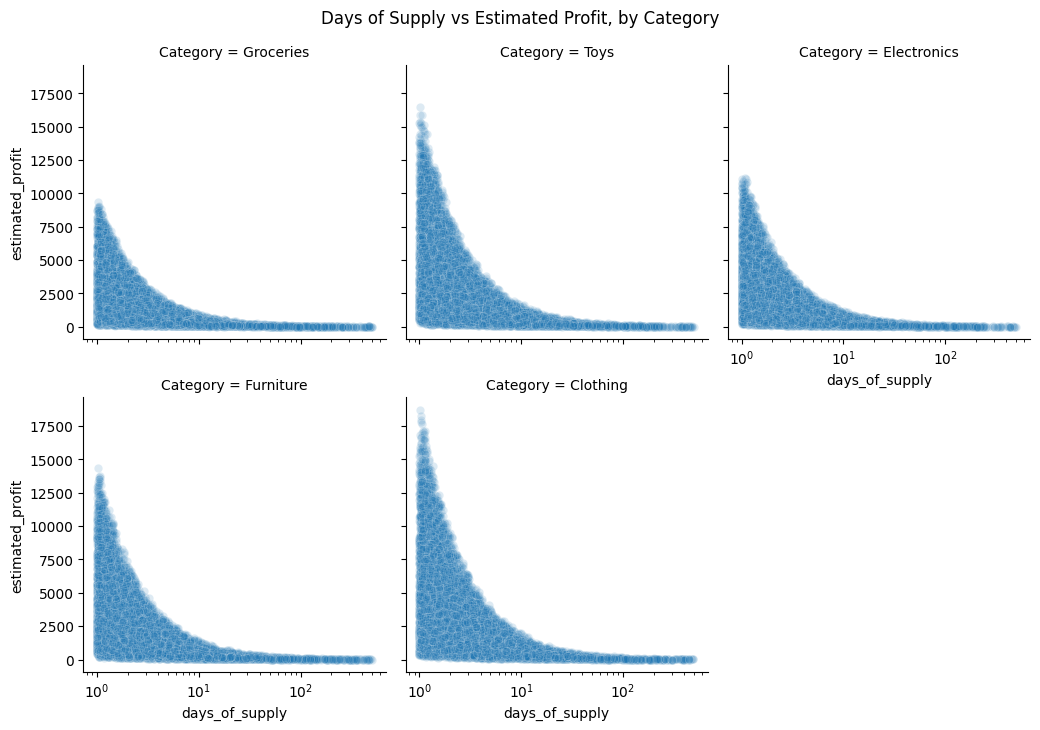

In [ ]:
g = sns.relplot(
    data=df, x='days_of_supply', y='estimated_profit',
    col='Category', col_wrap=3, alpha=0.15, height=3.5
)
g.set(xscale='log')
g.fig.suptitle('Days of Supply vs Estimated Profit, by Category', y=1.03)
plt.show()

## Summary of Findings

This analysis set out to understand which product categories are actually profitable
and how inventory management relates to that profitability, using a retail dataset of
73,100 transactions across five categories (Groceries, Clothing, Electronics, Furniture,
Toys).

**Revenue does not equal profit.** Furniture generated the highest raw revenue
(approximately ₹111.5M) of any category, but Clothing generated the highest
estimated profit (approximately ₹43.9M), because Clothing carries a substantially
higher assumed margin. Groceries, despite near-identical revenue to every other
category (approximately ₹110.9M), produced the lowest profit (approximately ₹22.2M)
due to thin grocery margins. This shows that revenue alone is a misleading metric
for prioritizing categories — margin-aware analysis tells a very different story
than a simple sales ranking.

**Procurement is not demand-driven.** A full correlation analysis found that Units
Ordered has an almost exactly zero correlation with both Units Sold (-0.001) and
Demand Forecast (-0.001) — meaning restocking decisions appear disconnected from
actual demand signals. This holds consistently across every category: Units Ordered
runs roughly 19-20% below Units Sold in every single category, with no category
performing meaningfully better or worse than another. This points to a systemic,
company-wide replenishment process that isn't responding to demand, rather than an
isolated issue in one product line.

**Slow-moving inventory captures significantly less profit.** Using a days-of-supply
metric (Inventory Level ÷ Units Sold), estimated profit shows a strong negative
Spearman correlation (-0.65) with days-of-supply — products with a higher days-of-supply
consistently capture far less profit than fast-turning items. This pattern held
consistently across all five categories when examined separately, confirming it's a
structural pattern rather than a category-specific one. It's worth noting this
relationship is partly mechanical (Units Sold appears in the calculation of both
variables), but the underlying business reality it reflects — that slow-moving stock
represents real lost profit potential — is genuine and actionable.

**Data limitation:** the dataset has no cost/COGS column, so profit figures throughout
this analysis are estimates based on assumed category-level margins (documented in the
methodology). Additionally, per-product inventory levels appeared near-uniformly
distributed across all products, which prevented reliable identification of specific
overstocked SKUs — this analysis instead focused on demand-driven, category-level, and
company-wide patterns, which the data supported much more robustly.

**Recommendation:** the retailer should investigate why procurement volume doesn't
track actual demand or forecast signals, since this disconnect appears to be a primary
driver of both the ordering gap and the profit loss associated with slow-moving
inventory. Aligning replenishment more closely with Demand Forecast (which correlates
almost perfectly with actual Units Sold at 0.997) represents a concrete, low-risk
starting point for improvement.